# Round Win Probability — Training Notebook

Trains all models on a single map's preprocessed dataset.
Edit the **two config blocks** in Section 0 (map name + tournament split) and run top-to-bottom.

**Models trained:**
- Baselines: Constant predictor, Health-difference predictor (τ fitted on val)
- Vector: LightGBM
- Set: DeepSets, SetTransformer
- Graph: GCNSimple, GAT
- Temporal: TemporalGNN (Section 9 — separate session)

**NNConv GCN excluded** — confirmed negative result on de_dust2, not retrained.

---
Sections: 0 Config | 1 Data | 2 Datasets | 3 Models | 4 Helpers | 5 Train | 6 Reload | 7 Results | 8 Plots | 9 TemporalGNN

## 0. Imports & Config

In [1]:
!pip install torch_geometric -q


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.7/63.7 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 83.8 MB/s eta 0:00:00


In [2]:
import os, json, random, time, warnings
from pathlib import Path
from copy import deepcopy

import numpy as np
import pandas as pd
import scipy.optimize
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam
from torch_geometric.data import Data, Batch
from torch_geometric.loader import DataLoader as PyGLoader
from torch_geometric.nn import GCNConv, GATConv, NNConv, global_mean_pool, BatchNorm
from torch_geometric.utils import dropout_edge
import lightgbm as lgb
from sklearn.metrics import log_loss
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

warnings.filterwarnings('ignore')

from google.colab import drive
drive.mount('/content/drive')

import sys
BASE = Path('/content/drive/MyDrive/magisterka')
sys.path.insert(0, str(BASE))

from dataset import (
    load_processed_matches, flatten_to_states,
    VectorDataset, SetDataset, SetNormaliser,
    GraphDataset, TemporalGraphDataset, temporal_collate_fn,
    build_datasets,
)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')


Mounted at /content/drive
Device: cuda


### ✏️ Edit here — map name

In [3]:
# ── MAP CONFIGURATION ────────────────────────────────────────────────────
MAP_NAME = 'inferno'   # change per map

PROCESSED_DIR  = BASE / 'data'        / MAP_NAME
CHECKPOINT_DIR = BASE / 'checkpoints' / MAP_NAME
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

S1_DIR = PROCESSED_DIR / 'season1'
S2_DIR = PROCESSED_DIR / 'season2'

print(f'Map:            de_{MAP_NAME}')
print(f'Checkpoint dir: {CHECKPOINT_DIR}')
print(f'Season 1 exists: {S1_DIR.exists()}')
print(f'Season 2 exists: {S2_DIR.exists()}')

# ── Hyperparameters ───────────────────────────────────────────────────────
# Neural model settings match ESTA paper (Xenopoulos & Silva, 2022):
#   lr=1e-3, batch_size=32, epochs=100, early_stopping=10
# LightGBM uses tuned params (num_leaves=63, lr=0.05, feature_fraction=0.9)
# rather than ESTA's LGBMClassifier defaults — these are strictly better.
CFG = dict(
    hidden             = 128,
    batch_size         = 32,      # ESTA: 32
    lr                 = 1e-3,    # ESTA: 0.001
    lr_temporal        = 3e-4,
    weight_decay       = 1e-4,
    grad_clip          = 1.0,
    grad_clip_temporal = 0.5,
    epochs             = 100,     # ESTA: 100
    patience           = 10,      # ESTA: early_stopping_rounds=10
    ece_bins           = 10,
    max_seq_len        = 80,
)

# ── Graph-model overrides (combat overfitting) ────────────────────────────
# Graph models on a single map (~313 training matches) overfit much faster
# than set/vector models. The overrides below are applied in the training
# cells; CFG remains unchanged so baselines and set models are unaffected.
#
#   hidden_graph   : 64 instead of 128 — halves parameter count; the fully-
#                    connected 10-node graph is already expressive at 64-dim.
#   dropout_graph  : 0.5 instead of 0.3 — stronger regularisation on conv
#                    layers where overfitting originates.
#   drop_edge_p    : 0.5 instead of 0.3 — stochastically removes half the
#                    edges per step, preventing reliance on any single path.
#   weight_decay_graph : 1e-3 instead of 1e-4 — heavier L2 penalty.
#   patience_graph : 5 instead of 10 — best ckpt appears at ep 1-3;
#                    10-epoch patience wastes compute and can drift.
#   lr_warmup_gat  : GAT attention weights are unstable at a cold lr=1e-3;
#                    warm up for 5 epochs at lr=1e-4, then step to 1e-3.
GRAPH_CFG = dict(
    hidden         = 32,
    dropout_gcn    = 0.5,   # GCNSimple: higher dropout tolerated
    dropout_gat    = 0.3,
    drop_edge_p    = 0.5,
    weight_decay   = 1e-3,
    patience       = 5,
    lr_warmup_gat  = 1e-4,
    warmup_epochs  = 5,
)

TEMPORAL_CFG = dict(
    hidden         = 64,       # matches regularised GCNSimple
    num_node_feat  = 32,       # 32 player features + mean_visibility + mean_same_team
    lr             = 1e-4,     # reduced from 3e-4; NNConv needed higher lr to move at all
    weight_decay   = 1e-3,     # matches GRAPH_CFG
    grad_clip      = 0.5,
    dropout_gcn    = 0.5,
    drop_edge_p    = 0.5,
    max_seq_len    = 80,
    batch_size     = 16,       # halved from 32; sequences are T×graph, memory-heavy
    epochs         = 100,
    patience       = 10,
)
print(f'CFG:       {CFG}')
print(f'GRAPH_CFG: {GRAPH_CFG}')


Map:            de_inferno
Checkpoint dir: /content/drive/MyDrive/magisterka/checkpoints/inferno
Season 1 exists: True
Season 2 exists: True
CFG:       {'hidden': 128, 'batch_size': 32, 'lr': 0.001, 'lr_temporal': 0.0003, 'weight_decay': 0.0001, 'grad_clip': 1.0, 'grad_clip_temporal': 0.5, 'epochs': 100, 'patience': 10, 'ece_bins': 10, 'max_seq_len': 80}
GRAPH_CFG: {'hidden': 32, 'dropout_gcn': 0.5, 'dropout_gat': 0.3, 'drop_edge_p': 0.5, 'weight_decay': 0.001, 'patience': 5, 'lr_warmup_gat': 0.0001, 'warmup_epochs': 5}


## 1. Data Loading & Splitting

In [5]:
from tqdm import tqdm

def get_tournament(match_key: str) -> str:
    parts = match_key.split('_')
    for i in range(len(parts) - 1, 0, -1):
        if '-vs-' in parts[i]:
            return '_'.join(parts[:i])
    return parts[0]

def load_season(season_dir: Path) -> dict:
    data = {}
    if not season_dir.exists():
        print(f'  ⚠️  {season_dir} not found — skipping')
        return data
    for fname in tqdm(sorted(season_dir.glob('*.json')), desc=str(season_dir.name)):
        with open(fname) as f:
            data.update(json.load(f))
    return data

print('Loading data...')
s1_data = load_season(S1_DIR)
s2_data = load_season(S2_DIR)
print(f'Season 1: {len(s1_data):,} matches')
print(f'Season 2: {len(s2_data):,} matches')

s2_tournaments = sorted({get_tournament(k) for k in s2_data})
print(f'\nSeason 2 tournaments ({len(s2_tournaments)} total):')
for t in s2_tournaments:
    n = sum(1 for k in s2_data if get_tournament(k) == t)
    print(f'  {n:3d} matches  |  {t}')


Loading data...


season2: 100%|██████████| 203/203 [07:45<00:00,  2.30s/it]

Season 1: 226 matches
Season 2: 203 matches

Season 2 tournaments (27 total):
    6 matches  |  BLAST Bounty Season 2
    1 matches  |  BLAST Bounty Season 2 Finals
    9 matches  |  BLAST Open London
    5 matches  |  BLAST Open London Finals
    3 matches  |  BLAST Rivals Season 2
    3 matches  |  BLAST Rivals Season 2 Playoffs
   11 matches  |  CS Asia Championships
    5 matches  |  CS Asia Championships Playoffs
    6 matches  |  ESL Pro League Playoffs
   13 matches  |  ESL Pro League Stage 1
   10 matches  |  ESL Pro League Stage 2
   10 matches  |  Esports World Cup
   17 matches  |  FISSURE Playground 2
    3 matches  |  FISSURE Playground 2 Playoffs
   14 matches  |  IEM Chengdu
    5 matches  |  IEM Chengdu Playoffs
   10 matches  |  IEM Cologne
    2 matches  |  IEM Cologne Playoffs
   11 matches  |  IEM Cologne Stage 1
   14 matches  |  PGL Masters Bucharest
    5 matches  |  PGL Masters Bucharest Playoffs
    4 matches  |  StarLadder Major Playoffs
    8 matches  |  Star

### ✏️ Edit here — tournament split

In [6]:
TOURNAMENT_SPLIT = {
    # ── TRAIN ────────────────────────────────
    'StarLadder StarSeries Fall':       'train',
    'BLAST Bounty Season 2':            'train',
    'BLAST Bounty Season 2 Finals':     'train',
    'BLAST Open London':                'train',
    'BLAST Open London Finals':         'train',
    'Esports World Cup':                'train',
    'FISSURE Playground 2':             'train',
    'FISSURE Playground 2 Playoffs':    'train',
    'IEM Cologne':                      'train',
    'IEM Cologne Stage 1':              'train',
    'IEM Cologne Playoffs':             'train',
    'ESL Pro League Stage 1':           'train',
    # ── VAL ──────────────────────────────────
    'ESL Pro League Stage 2':           'val',
    'ESL Pro League Playoffs':          'val',
    'CS Asia Championships':            'val',
    'CS Asia Championships Playoffs':   'val',
    'IEM Chengdu':                      'val',
    'IEM Chengdu Playoffs':             'val',
    'PGL Masters Bucharest':            'val',
    'PGL Masters Bucharest Playoffs':   'val',
    'Thunderpick World Championship':   'val',
    'BLAST Rivals Season 2':            'val',
    'BLAST Rivals Season 2 Playoffs':   'val',
    # ── TEST (StarLadder Major) ───────────────
    'StarLadder Major Stage 1':         'test',
    'StarLadder Major Stage 2':         'test',
    'StarLadder Major Stage 3':         'test',
    'StarLadder Major Playoffs':        'test',
}
# TOURNAMENT_SPLIT = {
#    "BLAST Bounty Season 1": "train",
#    "BLAST Bounty Season 1 Finals": "train",
#    "IEM Katowice Play-in": "train",
#    "IEM Katowice": "train",
#    "IEM Katowice Playoffs": "train",
#    "PGL Cluj-Napoca": "train",
#    "ESL Pro League Season 21 Stage 1": "train",
#    "ESL Pro League Season 21 Stage 2": "train",
#   "ESL Pro League Season 21 Playoffs": "train",
#    "BLAST Open Lisbon": "train",
#    "BLAST Open Lisbon Playoffs":"train",
# "PGL Bucharest": "train",
#    "PGL Bucharest Playoffs": "train",
#    "YaLLa Compass Groups":"train",
#    "YaLLa Compass Playoffs":"train",
#     "IEM Melbourne": "train",
#    "IEM Melbourne Playoffs": "train",
#    "CCT Global Finals":"train",
#   "MESA Nomadic Masters Groups":"train",
#     "BLAST Rivals Season 1 Groups": "train",
#    "BLAST Rivals Season 1 Playoffs": "train",
#    "Asian Champions League":"train",

#     "PGL Astana": "val",
#    "PGL Astana Playoffs": "val",
#     "IEM Dallas": "val",
#    "BLAST Major Stage 1": "val",

#    "BLAST Major Stage 2": "test",
#    "BLAST Major": "test",
#    "BLAST Major Playoffs": "test",
#    "FISSURE Playground 1": "test",
#    "FISSURE Playground 1 Playoffs": "test",
# }


# TOURNAMENT_SPLIT = {
#     'StarLadder StarSeries Fall':       'train',
#     'BLAST Bounty Season 2':            'train',
#     'BLAST Bounty Season 2 Finals':     'train',
#     'BLAST Open London':                'train',
#     'BLAST Open London Finals':         'train',
#     'Esports World Cup':                'train',
#     'FISSURE Playground 2':             'train',
#     'FISSURE Playground 2 Playoffs':    'train',
#     'IEM Cologne':                      'train',
#     'IEM Cologne Stage 1':              'train',
#     'IEM Cologne Playoffs':             'train',
#     'ESL Pro League Stage 1':           'train',
#     'ESL Pro League Stage 2':           'train',
#     'ESL Pro League Playoffs':          'train',
#     'CS Asia Championships':            'train',
#     'CS Asia Championships Playoffs':   'train',
#     'IEM Chengdu':                      'train',
#     'IEM Chengdu Playoffs':             'train',
#     'PGL Masters Bucharest':            'val',
#     'PGL Masters Bucharest Playoffs':   'val',
#     'Thunderpick World Championship':   'val',
#     'BLAST Rivals Season 2':            'val',
#     'BLAST Rivals Season 2 Playoffs':   'val',
#     'StarLadder Major Stage 1':         'test',
#     'StarLadder Major Stage 2':         'test',
#     'StarLadder Major Stage 3':         'test',
#     'StarLadder Major Playoffs':        'test',
# }


train_data, val_data, test_data = dict(s1_data), {}, {}
unassigned = []
for key, match in s2_data.items():
    t = get_tournament(key)
    split = TOURNAMENT_SPLIT.get(t)
    if   split == 'train': train_data[key] = match
    elif split == 'val':   val_data[key]   = match
    elif split == 'test':  test_data[key]  = match
    else:                  unassigned.append((t, key))

if unassigned:
    print(f'⚠️  {len(unassigned)} unassigned — add to TOURNAMENT_SPLIT:')
    for t, _ in sorted(set((t, '') for t, _ in unassigned)): print(f'   {t}')

def count_rounds(d): return sum(len({r.get('roundNum') for r in v['df']}) for v in d.values())
def count_states(d): return sum(len(v['Y']) for v in d.values())

print(f'\n=== Split Summary — de_{MAP_NAME} ===')
for name, d in [('Train', train_data), ('Val', val_data), ('Test', test_data)]:
    print(f'  {name:<5}: {len(d):4d} matches | {count_rounds(d):>6,} rounds | {count_states(d):>10,} states')



=== Split Summary — de_inferno ===
  Train:  322 matches |  7,030 rounds |    854,837 states
  Val  :   79 matches |  1,736 rounds |    209,241 states
  Test :   28 matches |    573 rounds |     70,640 states


## 2. Dataset Construction

In [7]:
datasets = build_datasets(
    train_data, val_data, test_data,
    temporal=False,
    max_seq_len=CFG['max_seq_len'],
)
normaliser_path = CHECKPOINT_DIR / 'normaliser'
datasets['set']['normaliser'].save(str(normaliser_path))
print(f'Datasets ready. Normaliser saved → {normaliser_path}.npz')


Datasets ready. Normaliser saved → /content/drive/MyDrive/magisterka/checkpoints/inferno/normaliser.npz


## 3. Model Definitions

### 3.1 DeepSets

In [8]:
class DeepSets(nn.Module):
    """
    DeepSets (Zaheer et al., 2017).
    Hyperparameters consistent with ESTA paper:
      lr=1e-3, batch_size=32, epochs=100, early_stopping=10.
    hidden=128 (our extension; ESTA used 64 — increased for richer representation).
    Dropout=0.3 added to regularise against correlated game states.
    """
    def __init__(self, in_features=32, hidden=128, dropout=0.3):
        super().__init__()
        self.phi = nn.Sequential(
            nn.Linear(in_features, hidden), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, hidden),
        )
        self.rho = nn.Sequential(
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, x):
        return self.rho(self.phi(x).mean(dim=1))


### 3.2 SetTransformer

In [9]:
class MultiheadAttentionBlock(nn.Module):
    def __init__(self, d_model, num_heads, dropout=0.1):
        super().__init__()
        self.attn  = nn.MultiheadAttention(d_model, num_heads, batch_first=True, dropout=dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.ff    = nn.Sequential(nn.Linear(d_model, d_model), nn.ReLU(),
                                   nn.Dropout(dropout), nn.Linear(d_model, d_model))
        self.norm2 = nn.LayerNorm(d_model)

    def forward(self, x):
        attn_out, _ = self.attn(x, x, x)
        x = self.norm1(x + attn_out)
        return self.norm2(x + self.ff(x))


class InducedSetAttentionBlock(nn.Module):
    def __init__(self, d_model, num_heads, num_inds=4, dropout=0.1):
        super().__init__()
        self.I    = nn.Parameter(torch.randn(1, num_inds, d_model))
        self.mab0 = MultiheadAttentionBlock(d_model, num_heads, dropout)
        self.mab1 = MultiheadAttentionBlock(d_model, num_heads, dropout)

    def forward(self, x):
        B = x.size(0)
        H = self.mab0(torch.cat([self.I.expand(B, -1, -1), x], dim=1))[:, :self.I.size(1)]
        return self.mab1(torch.cat([x, H], dim=1))[:, :x.size(1)]


class PoolingByMultiheadAttention(nn.Module):
    def __init__(self, d_model, num_heads, k=1, dropout=0.1):
        super().__init__()
        self.S   = nn.Parameter(torch.randn(1, k, d_model))
        self.mab = MultiheadAttentionBlock(d_model, num_heads, dropout)

    def forward(self, x):
        B = x.size(0)
        return self.mab(torch.cat([self.S.expand(B, -1, -1), x], dim=1))[:, :self.S.size(1)]


class SetTransformer(nn.Module):
    """
    Set Transformer (Lee et al., 2019).
    Hyperparameters consistent with ESTA paper:
      lr=1e-3, batch_size=32, epochs=100, early_stopping=10.
    num_heads=1, num_inds=4 (ESTA defaults).
    """
    def __init__(self, in_features=32, hidden=128, num_heads=1, num_inds=4, dropout=0.1):
        super().__init__()
        self.embed   = nn.Linear(in_features, hidden)
        self.encoder = InducedSetAttentionBlock(hidden, num_heads, num_inds, dropout)
        self.decoder = PoolingByMultiheadAttention(hidden, num_heads, k=1, dropout=dropout)
        self.head    = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden, 1))

    def forward(self, x):
        x = F.relu(self.embed(x))
        x = self.encoder(x)
        x = self.decoder(x).squeeze(1)
        return self.head(x)


### 3.3 GCNSimple

In [10]:
class GCNSimple(nn.Module):
    """
    Two-layer GCN with scalar edge weights (Kipf & Welling, 2017).
    Edge features: inv_geodesic_dist as scalar weight; visibility + same_team
    mean-aggregated onto node features (node augmentation trick).

    Regularisation vs. original:
      - dropout     : 0.3 → 0.5  (conv layers are the overfitting hotspot)
      - drop_edge_p : 0.3 → 0.5  (forces reliance on multiple graph paths)
      - hidden      : 128 → 64   (halves parameters; set via GRAPH_CFG)
    """
    def __init__(self, hidden=64, num_node_features=32, dropout=0.5, drop_edge_p=0.5):
        super().__init__()
        self.drop_edge_p = drop_edge_p
        self.conv1 = GCNConv(num_node_features + 2, hidden)
        self.bn1   = BatchNorm(hidden)
        self.conv2 = GCNConv(hidden, hidden)
        self.bn2   = BatchNorm(hidden)
        self.mlp   = nn.Sequential(
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, data):
        x, ei, ea, batch = data.x, data.edge_index, data.edge_attr, data.batch
        if self.training:
            ei, edge_mask = dropout_edge(ei, p=self.drop_edge_p, training=True)
            ea = ea[edge_mask]
        n   = x.size(0)
        src = ei[0]
        vis_agg  = torch.zeros(n, 1, device=x.device)
        team_agg = torch.zeros(n, 1, device=x.device)
        count    = torch.zeros(n, 1, device=x.device)
        ones     = torch.ones(src.size(0), 1, device=x.device)
        vis_agg.scatter_add_(0, src.unsqueeze(1), ea[:, 1].unsqueeze(1))
        team_agg.scatter_add_(0, src.unsqueeze(1), ea[:, 2].unsqueeze(1))
        count.scatter_add_(0, src.unsqueeze(1), ones)
        count = count.clamp(min=1)
        x_aug = torch.cat([x, vis_agg / count, team_agg / count], dim=1)
        ew    = ea[:, 0].clamp(max=10.0)
        x_aug = F.relu(self.bn1(self.conv1(x_aug, ei, ew)))
        x_aug = F.relu(self.bn2(self.conv2(x_aug, ei, ew)))
        return self.mlp(global_mean_pool(x_aug, batch))


### 3.4 GAT

In [11]:
class GAT(nn.Module):
    """
    Two-layer Graph Attention Network (Veličković et al., 2018).
    4 heads × 16 head-dim = 64-dim output (hidden reduced to 64 via GRAPH_CFG).
    Full 3-dim edge features passed to attention.

    Regularisation vs. original:
      - dropout     : 0.3 → 0.5  (attention weights overfit on small graphs)
      - drop_edge_p : 0.3 → 0.5
      - hidden      : 128 → 64   (4 heads × 16 = 64)
    LR warmup is handled in _train_loop_graph_gat, not here.
    """
    def __init__(self, hidden=64, num_node_features=32, num_edge_features=3,
                 heads=4, dropout=0.5, drop_edge_p=0.5):
        super().__init__()
        self.drop_edge_p = drop_edge_p
        head_dim = hidden // heads
        self.conv1 = GATConv(num_node_features, head_dim, heads=heads,
                             edge_dim=num_edge_features, concat=True, dropout=dropout)
        self.bn1   = BatchNorm(hidden)
        self.conv2 = GATConv(hidden, head_dim, heads=heads,
                             edge_dim=num_edge_features, concat=True, dropout=dropout)
        self.bn2   = BatchNorm(hidden)
        self.mlp   = nn.Sequential(
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )

    def forward(self, data):
        x, ei, ea, batch = data.x, data.edge_index, data.edge_attr, data.batch
        if self.training:
            ei, edge_mask = dropout_edge(ei, p=self.drop_edge_p, training=True)
            ea = ea[edge_mask]
        x = F.relu(self.bn1(self.conv1(x, ei, ea)))
        x = F.relu(self.bn2(self.conv2(x, ei, ea)))
        return self.mlp(global_mean_pool(x, batch))


### 3.5 TemporalGNN

In [ ]:
class TemporalGNN(nn.Module):
    """
    GCNSimple encoder + GRU temporal model.

    Input:  a pre-assembled sequence tensor of shape (batch, T, hidden),
            produced by temporal_collate_fn.
    Output: logit of shape (batch, 1) from the final GRU hidden state.

    The graph encoding step (encode_graphs) is called once per batch
    outside forward(), producing the sequence tensor passed into forward().
    This separation avoids the ptr reconstruction bug in the original design
    and makes the forward pass trivial for the GRU.
    """

    def __init__(self, hidden=64, num_node_feat=32, drop_edge_p=0.5, dropout_gcn=0.5):
        super().__init__()
        self.drop_edge_p = drop_edge_p

        # Graph encoder — identical structure to regularised static GCNSimple
        self.conv1 = GCNConv(num_node_feat, hidden)
        self.conv2 = GCNConv(hidden, hidden)
        self.bn1   = BatchNorm(hidden)
        self.bn2   = BatchNorm(hidden)
        self.drop  = nn.Dropout(dropout_gcn)

        # Temporal model
        self.gru  = nn.GRU(hidden, hidden, num_layers=1, batch_first=True)

        # Output head
        self.head = nn.Linear(hidden, 1)

    def encode_graph(self, data, apply_drop_edge=True):
        x, ei, ew = data.x, data.edge_index, data.edge_attr[:, 0]

        if apply_drop_edge and self.training:
            ei, edge_mask = dropout_edge(ei, p=self.drop_edge_p, training=True)
            ew = ew[edge_mask]

        x = F.relu(self.bn1(self.conv1(x, ei, ew)))
        x = self.drop(x)
        x = F.relu(self.bn2(self.conv2(x, ei, ew)))
        x = self.drop(x)
        return global_mean_pool(x, data.batch)

    def forward(self, seq, src_key_padding_mask):
        """
        seq:                    (batch, T, hidden) — pre-assembled by collate_fn
        src_key_padding_mask:   (batch, T) bool — True where timestep is padding

        Returns logit (batch, 1) from the last *valid* GRU hidden state.
        """
        gru_out, _ = self.gru(seq)               # (batch, T, hidden)

        # Gather the last non-padded hidden state for each sequence
        # lengths[b] = number of valid (non-padded) timesteps for sample b
        lengths = (~src_key_padding_mask).sum(dim=1).clamp(min=1)  # (batch,)
        idx = (lengths - 1).unsqueeze(1).unsqueeze(2).expand(-1, 1, gru_out.size(2))
        last = gru_out.gather(1, idx).squeeze(1)  # (batch, hidden)

        return self.head(last)                    # (batch, 1)


# ── COLLATE ───────────────────────────────────────────────────────────────────

def temporal_collate_fn(batch, model, device, max_seq_len=80):
    B  = len(batch)
    H  = model.gru.hidden_size
    T  = max_seq_len

    seq    = torch.zeros(B, T, H, device=device)
    mask   = torch.ones(B, T, dtype=torch.bool, device=device)
    labels = torch.zeros(B, dtype=torch.long)

    # Encode graphs without DropEdge regardless of model.training state
    with torch.no_grad():
        for b, (round_graphs, label) in enumerate(batch):
            labels[b] = label
            valid_len  = min(len(round_graphs), T)
            if valid_len == 0:
                continue

            from torch_geometric.data import Batch as PyGBatch
            g_batch = PyGBatch.from_data_list(round_graphs[:valid_len]).to(device)

            # Pass encode_graph with training=False to skip DropEdge
            embs = model.encode_graph(g_batch, apply_drop_edge=False)
            seq[b, :valid_len]  = embs
            mask[b, :valid_len] = False

    return seq, mask, labels

## 4. Training Helpers

In [12]:
def compute_ece(y_true, y_prob, n_bins=10):
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece, n = 0.0, len(y_true)
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (y_prob >= lo) & (y_prob < hi)
        if mask.sum() == 0: continue
        ece += mask.sum() / n * abs(y_true[mask].mean() - y_prob[mask].mean())
    return float(ece)


def evaluate_numpy(y_true, y_prob, label=''):
    ll  = log_loss(y_true, y_prob)
    ece = compute_ece(y_true, y_prob, CFG['ece_bins'])
    print(f'  [{label}]  LL={ll:.4f}  ECE={ece:.4f}')
    return {'log_loss': ll, 'ece': ece}


@torch.no_grad()
def predict_set_model(model, batches):
    model.eval()
    probs, trues = [], []
    for xb, yb in batches:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        probs.append(torch.sigmoid(model(xb)).cpu().numpy().flatten())
        trues.append(yb.cpu().numpy().flatten())
    return np.concatenate(trues), np.concatenate(probs)


@torch.no_grad()
def predict_graph_model(model, loader):
    model.eval()
    probs, trues = [], []
    for batch in loader:
        batch = batch.to(DEVICE)
        probs.append(torch.sigmoid(model(batch)).cpu().numpy().flatten())
        trues.append(batch.y.cpu().numpy().flatten())
    return np.concatenate(trues), np.concatenate(probs)


def _train_loop_set(model, train_ds, val_ds, name, lr, grad_clip):
    model = model.to(DEVICE)
    optim = Adam(model.parameters(), lr=lr, weight_decay=CFG['weight_decay'])
    crit  = nn.BCEWithLogitsLoss()
    ckpt  = CHECKPOINT_DIR / f'{name}.pt'
    best_val, best_ep, no_improve = float('inf'), 0, 0
    if ckpt.exists():
        print(f'  Checkpoint found → loading {ckpt.name}')
        model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
        return model
    for ep in range(1, CFG['epochs'] + 1):
        model.train()
        tot_loss, tot_n = 0.0, 0
        for xb, yb in train_ds.make_batches(CFG['batch_size'], shuffle=True):
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optim.zero_grad()
            loss = crit(model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            optim.step()
            tot_loss += loss.item() * xb.size(0); tot_n += xb.size(0)
        y_true, y_prob = predict_set_model(model, val_ds.make_batches(CFG['batch_size']))
        val_ll = log_loss(y_true, y_prob)
        print(f'  Epoch {ep:3d}  train LL={tot_loss/tot_n:.4f}  val LL={val_ll:.4f}')
        if val_ll < best_val:
            best_val, best_ep, no_improve = val_ll, ep, 0
            torch.save(model.state_dict(), ckpt)
        else:
            no_improve += 1
            if no_improve >= CFG['patience']:
                print(f'  Early stop at epoch {ep} (best epoch {best_ep}, val LL={best_val:.4f})')
                break
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    return model


def _train_loop_graph(model, train_ds, val_ds, name, lr, grad_clip):
    model = model.to(DEVICE)
    optim = Adam(model.parameters(), lr=lr, weight_decay=CFG['weight_decay'])
    crit  = nn.BCEWithLogitsLoss()
    ckpt  = CHECKPOINT_DIR / f'{name}.pt'
    train_loader = PyGLoader(train_ds, batch_size=CFG['batch_size'], shuffle=True)
    val_loader   = PyGLoader(val_ds,   batch_size=CFG['batch_size'], shuffle=False)
    best_val, best_ep, no_improve = float('inf'), 0, 0
    if ckpt.exists():
        print(f'  Checkpoint found → loading {ckpt.name}')
        model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
        return model
    for ep in range(1, CFG['epochs'] + 1):
        model.train()
        tot_loss, tot_n = 0.0, 0
        for batch in train_loader:
            batch = batch.to(DEVICE)
            optim.zero_grad()
            loss = crit(model(batch), batch.y.float().unsqueeze(1))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            optim.step()
            tot_loss += loss.item() * batch.num_graphs; tot_n += batch.num_graphs
        y_true, y_prob = predict_graph_model(model, val_loader)
        val_ll = log_loss(y_true, y_prob)
        print(f'  Epoch {ep:3d}  train LL={tot_loss/tot_n:.4f}  val LL={val_ll:.4f}')
        if val_ll < best_val:
            best_val, best_ep, no_improve = val_ll, ep, 0
            torch.save(model.state_dict(), ckpt)
        else:
            no_improve += 1
            if no_improve >= CFG['patience']:
                print(f'  Early stop at epoch {ep} (best epoch {best_ep}, val LL={best_val:.4f})')
                break
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    return model


def train_set_model(model, name):
    return _train_loop_set(model, datasets['set']['train'], datasets['set']['val'],
                           name, CFG['lr'], CFG['grad_clip'])


def train_graph_model(model, name):
    return _train_loop_graph(model, datasets['graph']['train'], datasets['graph']['val'],
                             name, CFG['lr'], CFG['grad_clip'])


print('Training helpers defined.')


def _train_loop_graph_regularised(model, train_ds, val_ds, name, lr, weight_decay, patience):
    """
    Graph training loop with graph-specific regularisation overrides.
    Differences from _train_loop_graph:
      - weight_decay : uses GRAPH_CFG['weight_decay'] (1e-3) instead of CFG['weight_decay']
      - patience     : uses GRAPH_CFG['patience'] (5) — graph models peak at ep 1-3
      - ReduceLROnPlateau scheduler : halves lr on 3 consecutive val-loss plateau steps,
        allowing the model to explore near the optimum rather than diverging past it
    """
    model = model.to(DEVICE)
    optim = Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optim, mode='min', factor=0.5, patience=3)
    crit  = nn.BCEWithLogitsLoss()
    ckpt  = CHECKPOINT_DIR / f'{name}.pt'
    train_loader = PyGLoader(train_ds, batch_size=CFG['batch_size'], shuffle=True)
    val_loader   = PyGLoader(val_ds,   batch_size=CFG['batch_size'], shuffle=False)
    best_val, best_ep, no_improve = float('inf'), 0, 0
    if ckpt.exists():
        print(f'  Checkpoint found → loading {ckpt.name}')
        model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
        return model
    for ep in range(1, CFG['epochs'] + 1):
        model.train()
        tot_loss, tot_n = 0.0, 0
        for batch in train_loader:
            batch = batch.to(DEVICE)
            optim.zero_grad()
            loss = crit(model(batch), batch.y.float().unsqueeze(1))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG['grad_clip'])
            optim.step()
            tot_loss += loss.item() * batch.num_graphs; tot_n += batch.num_graphs
        y_true, y_prob = predict_graph_model(model, val_loader)
        val_ll = log_loss(y_true, y_prob)
        cur_lr = optim.param_groups[0]['lr']
        print(f'  Epoch {ep:3d}  train LL={tot_loss/tot_n:.4f}  val LL={val_ll:.4f}  lr={cur_lr:.2e}')
        scheduler.step(val_ll)
        if val_ll < best_val:
            best_val, best_ep, no_improve = val_ll, ep, 0
            torch.save(model.state_dict(), ckpt)
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f'  Early stop at epoch {ep} (best epoch {best_ep}, val LL={best_val:.4f})')
                break
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    return model


def _train_loop_graph_gat(model, train_ds, val_ds, name):
    """
    GAT-specific training loop with LR warmup.
    GAT attention weights are unstable at a cold lr=1e-3; the warmup phase
    (GRAPH_CFG['warmup_epochs'] epochs at GRAPH_CFG['lr_warmup_gat']=1e-4)
    stabilises the initial attention distributions before the full lr is applied.
    After warmup, delegates to _train_loop_graph_regularised.
    """
    model = model.to(DEVICE)
    ckpt = CHECKPOINT_DIR / f'{name}.pt'
    if ckpt.exists():
        print(f'  Checkpoint found → loading {ckpt.name}')
        model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
        return model

    warmup_epochs = GRAPH_CFG['warmup_epochs']
    warmup_lr     = GRAPH_CFG['lr_warmup_gat']
    print(f'  Warmup: {warmup_epochs} epochs at lr={warmup_lr:.1e}')
    optim_warm = Adam(model.parameters(), lr=warmup_lr,
                      weight_decay=GRAPH_CFG['weight_decay'])
    crit  = nn.BCEWithLogitsLoss()
    train_loader = PyGLoader(train_ds, batch_size=CFG['batch_size'], shuffle=True)
    for ep in range(1, warmup_epochs + 1):
        model.train()
        tot_loss, tot_n = 0.0, 0
        for batch in train_loader:
            batch = batch.to(DEVICE)
            optim_warm.zero_grad()
            loss = crit(model(batch), batch.y.float().unsqueeze(1))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG['grad_clip'])
            optim_warm.step()
            tot_loss += loss.item() * batch.num_graphs; tot_n += batch.num_graphs
        print(f'  Warmup epoch {ep:2d}  train LL={tot_loss/tot_n:.4f}')

    print(f'  Warmup done — switching to lr={CFG["lr"]:.1e} with ReduceLROnPlateau')
    return _train_loop_graph_regularised(
        model, train_ds, val_ds, name,
        lr=CFG['lr'],
        weight_decay=GRAPH_CFG['weight_decay'],
        patience=GRAPH_CFG['patience'],
    )


def train_graph_model_regularised(model, name):
    return _train_loop_graph_regularised(
        model, datasets['graph']['train'], datasets['graph']['val'],
        name, CFG['lr'], GRAPH_CFG['weight_decay'], GRAPH_CFG['patience'],
    )


def train_gat_model_regularised(model, name):
    return _train_loop_graph_gat(
        model, datasets['graph']['train'], datasets['graph']['val'], name,
    )


Training helpers defined.


## 5. Train All Models

All training cells are idempotent: if a checkpoint exists it is loaded instead of retraining.

### 5.1 Baselines

In [13]:
# ── Constant predictor ───────────────────────────────────────────────────
# Always predicts CT win with probability 1.0.
# LL = -log(p_CT) where p_CT is empirical CT win rate on test set.
# ECE = |p_CT - 1.0| (perfectly miscalibrated toward CT).

X_test, y_test = datasets['vector']['test'].get_features()
y_test_arr = y_test.values if hasattr(y_test, 'values') else np.array(y_test)

ct_win_rate = y_test_arr.mean()
constant_prob = np.ones(len(y_test_arr))   # always predict 1.0
# clip to avoid log(0) — log_loss clips internally but be explicit
constant_prob_clipped = np.clip(constant_prob, 1e-7, 1 - 1e-7)

constant_results = evaluate_numpy(y_test_arr, constant_prob_clipped, 'Constant/test')
print(f'  CT win rate on test set: {ct_win_rate:.4f}')

# ── Health-difference predictor ───────────────────────────────────────────
# p_hat = sigmoid((ctHp - tHp) / tau)
# tau is fitted on the validation set by minimising log loss.

X_val, y_val = datasets['vector']['val'].get_features()
y_val_arr = y_val.values if hasattr(y_val, 'values') else np.array(y_val)

def hp_diff_ll(log_tau, X, y):
    tau = np.exp(log_tau[0])   # keep tau > 0
    delta_h = X['ctHp'].values - X['tHp'].values
    prob = 1.0 / (1.0 + np.exp(-delta_h / tau))
    prob = np.clip(prob, 1e-7, 1 - 1e-7)
    return log_loss(y, prob)

opt = scipy.optimize.minimize(
    hp_diff_ll, x0=[np.log(100.0)],
    args=(X_val, y_val_arr),
    method='Nelder-Mead',
)
tau_opt = np.exp(opt.x[0])
print(f'  HP-diff: fitted tau={tau_opt:.2f} (val LL={opt.fun:.4f})')

delta_h_test = X_test['ctHp'].values - X_test['tHp'].values
hpdiff_prob  = 1.0 / (1.0 + np.exp(-delta_h_test / tau_opt))
hpdiff_prob  = np.clip(hpdiff_prob, 1e-7, 1 - 1e-7)
hpdiff_results = evaluate_numpy(y_test_arr, hpdiff_prob, 'HP-diff/test')

baseline_preds = {
    'Constant':  (y_test_arr, constant_prob_clipped),
    'HP-diff':   (y_test_arr, hpdiff_prob),
}
print('\nBaselines done.')


  [Constant/test]  LL=8.1284  ECE=0.5043
  CT win rate on test set: 0.4957
  HP-diff: fitted tau=82.27 (val LL=0.5518)
  [HP-diff/test]  LL=0.5490  ECE=0.0557

Baselines done.


### 5.2 LightGBM

In [14]:
print('=== LightGBM ===')
lgbm_ckpt = CHECKPOINT_DIR / 'lightgbm.txt'

X_train, y_train = datasets['vector']['train'].get_features()
# X_val, y_val, X_test, y_test already loaded in 5.1

if lgbm_ckpt.exists():
    print('  Checkpoint found → loading')
    lgbm_model = lgb.Booster(model_file=str(lgbm_ckpt))
else:
    lgb_train = lgb.Dataset(X_train, label=y_train)
    lgb_val   = lgb.Dataset(X_val,   label=y_val_arr, reference=lgb_train)
    lgbm_model = lgb.train(
        dict(objective='binary', metric='binary_logloss', num_leaves=63,
             learning_rate=0.05, feature_fraction=0.9, bagging_fraction=0.8,
             bagging_freq=5, verbose=-1, seed=SEED),
        lgb_train, num_boost_round=500, valid_sets=[lgb_val],
        callbacks=[lgb.early_stopping(CFG['patience'], verbose=True),
                   lgb.log_evaluation(period=20)],
    )
    lgbm_model.save_model(str(lgbm_ckpt))
    print(f'  Saved → {lgbm_ckpt}')

lgbm_results = {}
for split, X, y in [('val', X_val, y_val_arr), ('test', X_test, y_test_arr)]:
    lgbm_results[split] = evaluate_numpy(y, lgbm_model.predict(X), f'LightGBM/{split}')


=== LightGBM ===
Training until validation scores don't improve for 10 rounds
[20]	valid_0's binary_logloss: 0.518092
[40]	valid_0's binary_logloss: 0.475737
[60]	valid_0's binary_logloss: 0.463628
[80]	valid_0's binary_logloss: 0.460093
[100]	valid_0's binary_logloss: 0.458838
[120]	valid_0's binary_logloss: 0.45853
Early stopping, best iteration is:
[111]	valid_0's binary_logloss: 0.458345
  Saved → /content/drive/MyDrive/magisterka/checkpoints/inferno/lightgbm.txt
  [LightGBM/val]  LL=0.4583  ECE=0.0135
  [LightGBM/test]  LL=0.4659  ECE=0.0195


### 5.3 DeepSets

In [15]:
print('=== DeepSets ===')
deepsets_model = train_set_model(DeepSets(hidden=CFG['hidden']), 'deepsets')

deepsets_results = {}
for split, ds in [('val', datasets['set']['val']), ('test', datasets['set']['test'])]:
    y_true, y_prob = predict_set_model(deepsets_model, ds.make_batches(CFG['batch_size']))
    deepsets_results[split] = evaluate_numpy(y_true, y_prob, f'DeepSets/{split}')


=== DeepSets ===
  Epoch   1  train LL=0.4652  val LL=0.4601
  Epoch   2  train LL=0.4588  val LL=0.4552
  Epoch   3  train LL=0.4574  val LL=0.4510
  Epoch   4  train LL=0.4569  val LL=0.4575
  Epoch   5  train LL=0.4564  val LL=0.4505
  Epoch   6  train LL=0.4555  val LL=0.4525
  Epoch   7  train LL=0.4546  val LL=0.4521
  Epoch   8  train LL=0.4526  val LL=0.4477
  Epoch   9  train LL=0.4515  val LL=0.4617
  Epoch  10  train LL=0.4512  val LL=0.4509
  Epoch  11  train LL=0.4504  val LL=0.4559
  Epoch  12  train LL=0.4505  val LL=0.4527
  Epoch  13  train LL=0.4501  val LL=0.4486
  Epoch  14  train LL=0.4496  val LL=0.4628
  Epoch  15  train LL=0.4493  val LL=0.4495
  Epoch  16  train LL=0.4495  val LL=0.4484
  Epoch  17  train LL=0.4489  val LL=0.4524
  Epoch  18  train LL=0.4487  val LL=0.4506
  Early stop at epoch 18 (best epoch 8, val LL=0.4477)
  [DeepSets/val]  LL=0.4477  ECE=0.0130
  [DeepSets/test]  LL=0.4651  ECE=0.0241


### 5.4 SetTransformer

In [16]:
print('=== SetTransformer ===')
settransformer_model = train_set_model(
    SetTransformer(hidden=CFG['hidden'], num_heads=1), 'settransformer')

settransformer_results = {}
for split, ds in [('val', datasets['set']['val']), ('test', datasets['set']['test'])]:
    y_true, y_prob = predict_set_model(settransformer_model, ds.make_batches(CFG['batch_size']))
    settransformer_results[split] = evaluate_numpy(y_true, y_prob, f'SetTransformer/{split}')


=== SetTransformer ===
  Epoch   1  train LL=0.4566  val LL=0.4645
  Epoch   2  train LL=0.4327  val LL=0.5357
  Epoch   3  train LL=0.4183  val LL=0.4685
  Epoch   4  train LL=0.4054  val LL=0.5558
  Epoch   5  train LL=0.3947  val LL=0.5281
  Epoch   6  train LL=0.3851  val LL=0.5570
  Epoch   7  train LL=0.3776  val LL=0.5435
  Epoch   8  train LL=0.3712  val LL=0.5425
  Epoch   9  train LL=0.3664  val LL=0.5610
  Epoch  10  train LL=0.3616  val LL=0.5441
  Epoch  11  train LL=0.3585  val LL=0.5477
  Early stop at epoch 11 (best epoch 1, val LL=0.4645)
  [SetTransformer/val]  LL=0.4645  ECE=0.0388
  [SetTransformer/test]  LL=0.4892  ECE=0.0443


### 5.5 GCNSimple

In [17]:
print('=== GCNSimple (regularised) ===')
gcn_simple_model = train_graph_model_regularised(
    GCNSimple(
        hidden       = GRAPH_CFG['hidden'],
        dropout      = GRAPH_CFG['dropout_gcn'],
        drop_edge_p  = GRAPH_CFG['drop_edge_p'],
    ),
    'gcn_simple',
)

gcn_simple_results = {}
for split, ds in [('val', datasets['graph']['val']), ('test', datasets['graph']['test'])]:
    loader = PyGLoader(ds, batch_size=CFG['batch_size'], shuffle=False)
    y_true, y_prob = predict_graph_model(gcn_simple_model, loader)
    gcn_simple_results[split] = evaluate_numpy(y_true, y_prob, f'GCNSimple/{split}')


=== GCNSimple (regularised) ===
  Epoch   1  train LL=0.4711  val LL=0.4589  lr=1.00e-03
  Epoch   2  train LL=0.4649  val LL=0.4561  lr=1.00e-03
  Epoch   3  train LL=0.4644  val LL=0.4540  lr=1.00e-03
  Epoch   4  train LL=0.4638  val LL=0.4560  lr=1.00e-03
  Epoch   5  train LL=0.4635  val LL=0.4584  lr=1.00e-03
  Epoch   6  train LL=0.4633  val LL=0.4566  lr=1.00e-03
  Epoch   7  train LL=0.4631  val LL=0.4596  lr=1.00e-03
  Epoch   8  train LL=0.4596  val LL=0.4560  lr=5.00e-04
  Early stop at epoch 8 (best epoch 3, val LL=0.4540)
  [GCNSimple/val]  LL=0.4540  ECE=0.0191
  [GCNSimple/test]  LL=0.4642  ECE=0.0288


### 5.6 GAT

In [18]:
print('=== GAT (regularised + LR warmup) ===')
gat_model = train_gat_model_regularised(
    GAT(
        hidden       = GRAPH_CFG['hidden'],
        dropout      = GRAPH_CFG["dropout_gat"],
        drop_edge_p  = GRAPH_CFG['drop_edge_p'],
    ),
    'gat',
)

gat_results = {}
for split, ds in [('val', datasets['graph']['val']), ('test', datasets['graph']['test'])]:
    loader = PyGLoader(ds, batch_size=CFG['batch_size'], shuffle=False)
    y_true, y_prob = predict_graph_model(gat_model, loader)
    gat_results[split] = evaluate_numpy(y_true, y_prob, f'GAT/{split}')


=== GAT (regularised + LR warmup) ===
  Warmup: 5 epochs at lr=1.0e-04
  Warmup epoch  1  train LL=0.5431
  Warmup epoch  2  train LL=0.5215
  Warmup epoch  3  train LL=0.5172
  Warmup epoch  4  train LL=0.5144
  Warmup epoch  5  train LL=0.5132
  Warmup done — switching to lr=1.0e-03 with ReduceLROnPlateau
  Epoch   1  train LL=0.5187  val LL=0.4759  lr=1.00e-03
  Epoch   2  train LL=0.5164  val LL=0.4817  lr=1.00e-03
  Epoch   3  train LL=0.5162  val LL=0.4686  lr=1.00e-03
  Epoch   4  train LL=0.5155  val LL=0.4748  lr=1.00e-03
  Epoch   5  train LL=0.5157  val LL=0.4727  lr=1.00e-03
  Epoch   6  train LL=0.5156  val LL=0.4781  lr=1.00e-03
  Epoch   7  train LL=0.5153  val LL=0.4694  lr=1.00e-03
  Epoch   8  train LL=0.5121  val LL=0.4663  lr=5.00e-04
  Epoch   9  train LL=0.5124  val LL=0.4795  lr=5.00e-04
  Epoch  10  train LL=0.5123  val LL=0.4783  lr=5.00e-04
  Epoch  11  train LL=0.5121  val LL=0.4757  lr=5.00e-04
  Epoch  12  train LL=0.5128  val LL=0.4678  lr=5.00e-04
  Epoch

## 6. Load Checkpoints *(after session reset)*

In [19]:
lgbm_model = lgb.Booster(model_file=str(CHECKPOINT_DIR / 'lightgbm.txt'))
X_val,  y_val  = datasets['vector']['val'].get_features()
X_test, y_test = datasets['vector']['test'].get_features()
y_val_arr  = y_val.values  if hasattr(y_val,  'values') else np.array(y_val)
y_test_arr = y_test.values if hasattr(y_test, 'values') else np.array(y_test)

deepsets_model = DeepSets(hidden=128).to(DEVICE)
deepsets_model.load_state_dict(torch.load(CHECKPOINT_DIR / 'deepsets.pt', map_location=DEVICE))
deepsets_model.eval()

settransformer_model = SetTransformer(hidden=128, num_heads=1).to(DEVICE)
settransformer_model.load_state_dict(torch.load(CHECKPOINT_DIR / 'settransformer.pt', map_location=DEVICE))
settransformer_model.eval()

gcn_simple_model = GCNSimple(hidden=GRAPH_CFG['hidden'], dropout=GRAPH_CFG['dropout_gcn'], drop_edge_p=GRAPH_CFG['drop_edge_p']).to(DEVICE)
gcn_simple_model.load_state_dict(torch.load(CHECKPOINT_DIR / 'gcn_simple.pt', map_location=DEVICE))
gcn_simple_model.eval()

gat_model = GAT(hidden=GRAPH_CFG['hidden'], dropout=GRAPH_CFG['dropout_gat'], drop_edge_p=GRAPH_CFG['drop_edge_p']).to(DEVICE)
gat_model.load_state_dict(torch.load(CHECKPOINT_DIR / 'gat.pt', map_location=DEVICE))
gat_model.eval()

# Re-fit baselines (no checkpoint needed — fast)
ct_win_rate = y_test_arr.mean()
constant_prob_clipped = np.clip(np.ones(len(y_test_arr)), 1e-7, 1 - 1e-7)

opt = scipy.optimize.minimize(
    lambda log_tau, X, y: log_loss(y, np.clip(1/(1+np.exp(-(X['ctHp'].values-X['tHp'].values)/np.exp(log_tau[0]))), 1e-7, 1-1e-7)),
    x0=[np.log(100.0)], args=(X_val, y_val_arr), method='Nelder-Mead',
)
tau_opt = np.exp(opt.x[0])
delta_h_test = X_test['ctHp'].values - X_test['tHp'].values
hpdiff_prob  = np.clip(1/(1+np.exp(-delta_h_test/tau_opt)), 1e-7, 1-1e-7)
baseline_preds = {
    'Constant': (y_test_arr, constant_prob_clipped),
    'HP-diff':  (y_test_arr, hpdiff_prob),
}
print(f'All checkpoints loaded. tau={tau_opt:.2f}')


All checkpoints loaded. tau=82.27


## 7. Results Summary

In [20]:
test_preds = {}  # model_name -> (y_true, y_prob)

# Baselines
test_preds.update(baseline_preds)

# LightGBM
test_preds['LightGBM'] = (y_test_arr, lgbm_model.predict(X_test))

# Set models
for name, model in [('DeepSets', deepsets_model), ('SetTransformer', settransformer_model)]:
    test_preds[name] = predict_set_model(model, datasets['set']['test'].make_batches(CFG['batch_size']))

# Graph models
for name, model in [('GCNSimple', gcn_simple_model), ('GAT', gat_model)]:
    loader = PyGLoader(datasets['graph']['test'], batch_size=CFG['batch_size'], shuffle=False)
    test_preds[name] = predict_graph_model(model, loader)

MODEL_ORDER = ['Constant', 'HP-diff', 'LightGBM', 'DeepSets', 'SetTransformer', 'GCNSimple', 'GAT']

print(f'\n=== Test Set Results — de_{MAP_NAME} ===')
print(f'{"Model":<16}  {"LL":>8}  {"ECE":>8}')
print('-' * 38)
for name in MODEL_ORDER:
    if name not in test_preds: continue
    yt, yp = test_preds[name]
    print(f'{name:<16}  {log_loss(yt,yp):>8.4f}  {compute_ece(yt,yp):>8.4f}')



=== Test Set Results — de_inferno ===
Model                   LL       ECE
--------------------------------------
Constant            8.1284    0.5043
HP-diff             0.5490    0.0557
LightGBM            0.4659    0.0195
DeepSets            0.4651    0.0241
SetTransformer      0.4892    0.0443
GCNSimple           0.4642    0.0288
GAT                 0.4825    0.0236


## 8. Visualisations

### 8.1 Build time index

In [21]:
time_arr, bomb_arr = [], []
for match in test_data.values():
    for df_row in match['df']:
        time_arr.append(float(df_row.get('secondsSincePhaseStart', 0)))
        bomb_arr.append(int(df_row.get('bombPlanted', 0)))
time_arr = np.array(time_arr)
bomb_arr = np.array(bomb_arr)

print(f'time_arr length: {len(time_arr):,}')
# Baselines align by construction; check neural models
for name in ['LightGBM', 'DeepSets', 'SetTransformer', 'GCNSimple', 'GAT']:
    if name not in test_preds: continue
    yt, yp = test_preds[name]
    status = '✓' if len(yt) == len(time_arr) else f'⚠️  MISMATCH ({len(yt)})'
    print(f'  {name:<16} {status}')


time_arr length: 70,640
  LightGBM         ✓
  DeepSets         ✓
  SetTransformer   ✓
  GCNSimple        ✓
  GAT              ✓


### 8.2 Calibration curves

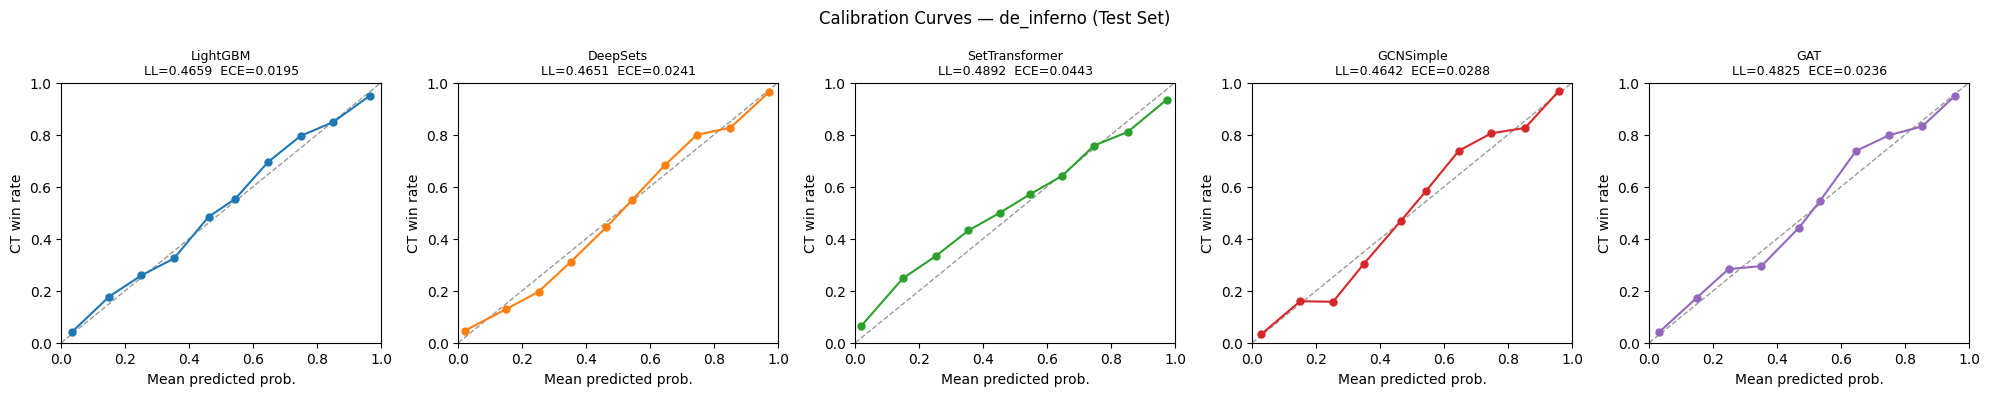

In [22]:
COLORS = {
    'Constant': 'lightgray', 'HP-diff': 'silver',
    'LightGBM': '#1f77b4', 'DeepSets': '#ff7f0e',
    'SetTransformer': '#2ca02c', 'GCNSimple': '#d62728', 'GAT': '#9467bd',
}

def calibration_curve(y_true, y_prob, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    mp, mt = [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (y_prob >= lo) & (y_prob < hi)
        if mask.sum() > 0:
            mp.append(y_prob[mask].mean()); mt.append(y_true[mask].mean())
    return np.array(mp), np.array(mt)

plot_models = ['LightGBM', 'DeepSets', 'SetTransformer', 'GCNSimple', 'GAT']
fig, axes = plt.subplots(1, len(plot_models), figsize=(4*len(plot_models), 4))
for ax, name in zip(axes, plot_models):
    if name not in test_preds: ax.set_visible(False); continue
    yt, yp = test_preds[name]
    mp, mt = calibration_curve(yt, yp)
    ax.plot([0,1],[0,1],'k--',lw=1,alpha=0.4)
    ax.plot(mp, mt, 'o-', color=COLORS[name], ms=5)
    ax.set_title(f'{name}\nLL={log_loss(yt,yp):.4f}  ECE={compute_ece(yt,yp):.4f}', fontsize=9)
    ax.set_xlabel('Mean predicted prob.'); ax.set_ylabel('CT win rate')
    ax.set_xlim(0,1); ax.set_ylim(0,1)
plt.suptitle(f'Calibration Curves — de_{MAP_NAME} (Test Set)', fontsize=12)
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_calibration.png', dpi=150, bbox_inches='tight')
plt.show()


### 8.3 Time-binned log loss

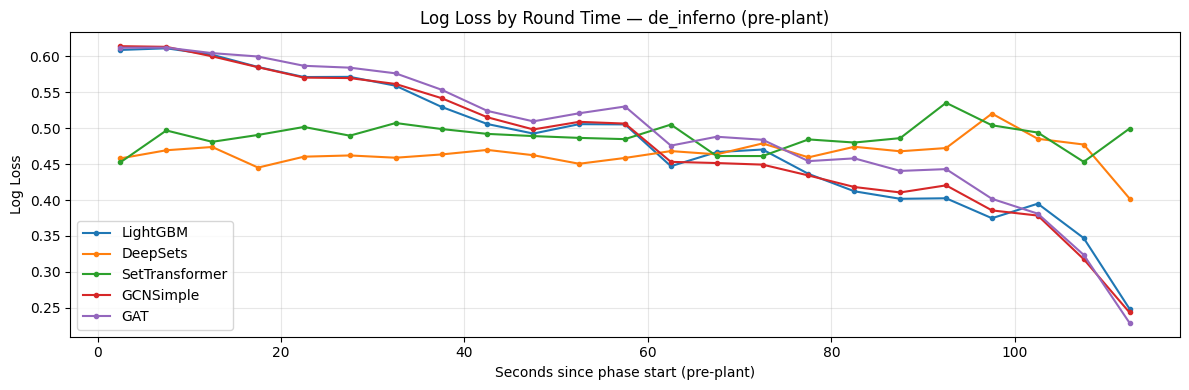

In [23]:
BIN_WIDTH = 5; MAX_TIME = 115
bin_edges   = np.arange(0, MAX_TIME + BIN_WIDTH, BIN_WIDTH)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
pre_plant_mask = (bomb_arr == 0)

fig, ax = plt.subplots(figsize=(12, 4))
# Skip Constant and HP-diff — no time alignment needed, they're trivial
for name in ['LightGBM', 'DeepSets', 'SetTransformer', 'GCNSimple', 'GAT']:
    if name not in test_preds: continue
    yt, yp = test_preds[name]
    if len(yt) != len(time_arr): print(f'  Skipping {name}'); continue
    ll_bins = []
    for lo, hi in zip(bin_edges[:-1], bin_edges[1:]):
        mask = pre_plant_mask & (time_arr >= lo) & (time_arr < hi)
        ll_bins.append(log_loss(yt[mask], yp[mask]) if mask.sum() >= 10 else np.nan)
    ax.plot(bin_centers, ll_bins, '-o', ms=3, lw=1.5, color=COLORS[name], label=name)
ax.set_xlabel('Seconds since phase start (pre-plant)')
ax.set_ylabel('Log Loss')
ax.set_title(f'Log Loss by Round Time — de_{MAP_NAME} (pre-plant)')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_ll_by_time.png', dpi=150, bbox_inches='tight')
plt.show()


### 8.4 Late-round log loss

Late pre-plant states (>=85s): 6,608
Post-plant states:                          11,993

Model              Full LL   Late pre-plant LL   Post-plant LL
--------------------------------------------------------------
Constant            8.1284                 n/a             n/a
HP-diff             0.5490                 n/a             n/a
LightGBM            0.4659              0.3824          0.2393
DeepSets            0.4651              0.4796          0.4666
SetTransformer      0.4892              0.5009          0.4895
GCNSimple           0.4642              0.3860          0.2238
GAT                 0.4825              0.4027          0.2534


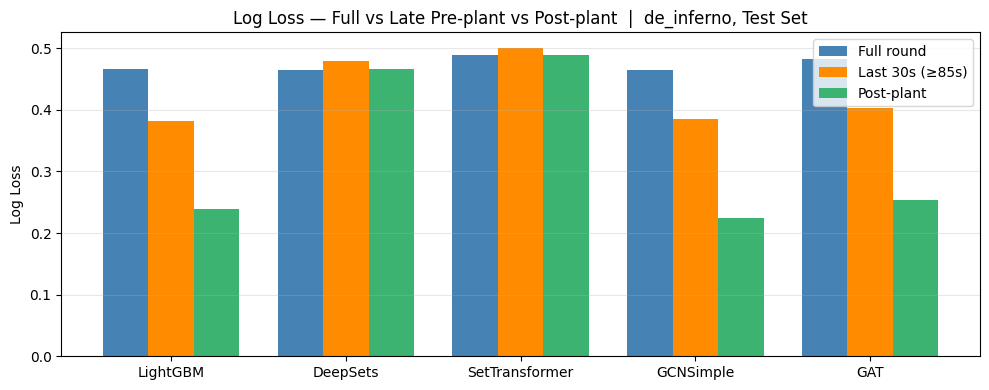

In [24]:
LATE_THRESHOLD = 85
late_mask  = pre_plant_mask & (time_arr >= LATE_THRESHOLD)
plant_mask = (bomb_arr == 1)

print(f'Late pre-plant states (>={LATE_THRESHOLD}s): {late_mask.sum():,}')
print(f'Post-plant states:                          {plant_mask.sum():,}')
print()

late_results = {}
print(f'{"Model":<16}  {"Full LL":>8}  {"Late pre-plant LL":>18}  {"Post-plant LL":>14}')
print('-' * 62)

# Baselines: compute directly (no time alignment needed)
for name in ['Constant', 'HP-diff']:
    yt, yp = test_preds[name]
    ll_f = log_loss(yt, yp)
    # For baselines, time-indexed subsets need separate arrays — skip late/plant breakdown
    late_results[name] = dict(full=ll_f, late=float('nan'), plant=float('nan'))
    print(f'{name:<16}  {ll_f:>8.4f}  {"n/a":>18}  {"n/a":>14}')

for name in ['LightGBM', 'DeepSets', 'SetTransformer', 'GCNSimple', 'GAT']:
    if name not in test_preds: continue
    yt, yp = test_preds[name]
    if len(yt) != len(time_arr): continue
    ll_f = log_loss(yt, yp)
    ll_l = log_loss(yt[late_mask],  yp[late_mask])  if late_mask.sum()  >= 10 else float('nan')
    ll_p = log_loss(yt[plant_mask], yp[plant_mask]) if plant_mask.sum() >= 10 else float('nan')
    late_results[name] = dict(full=ll_f, late=ll_l, plant=ll_p)
    print(f'{name:<16}  {ll_f:>8.4f}  {ll_l:>18.4f}  {ll_p:>14.4f}')

# Bar chart — neural models only (baselines shown as horizontal reference lines)
bar_models = [n for n in ['LightGBM', 'DeepSets', 'SetTransformer', 'GCNSimple', 'GAT']
              if n in late_results]
x = np.arange(len(bar_models)); w = 0.26
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(x-w, [late_results[n]['full']  for n in bar_models], w, label='Full round',   color='steelblue')
ax.bar(x,   [late_results[n]['late']  for n in bar_models], w, label=f'Last 30s (≥{LATE_THRESHOLD}s)', color='darkorange')
ax.bar(x+w, [late_results[n]['plant'] for n in bar_models], w, label='Post-plant',   color='mediumseagreen')
ax.set_xticks(x); ax.set_xticklabels(bar_models)
ax.set_ylabel('Log Loss')
ax.set_title(f'Log Loss — Full vs Late Pre-plant vs Post-plant  |  de_{MAP_NAME}, Test Set')
ax.legend(); ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'fig_ll_late_round.png', dpi=150, bbox_inches='tight')
plt.show()


### 8.5 Round win probability trace

In [ ]:
list(test_data.keys())[17]

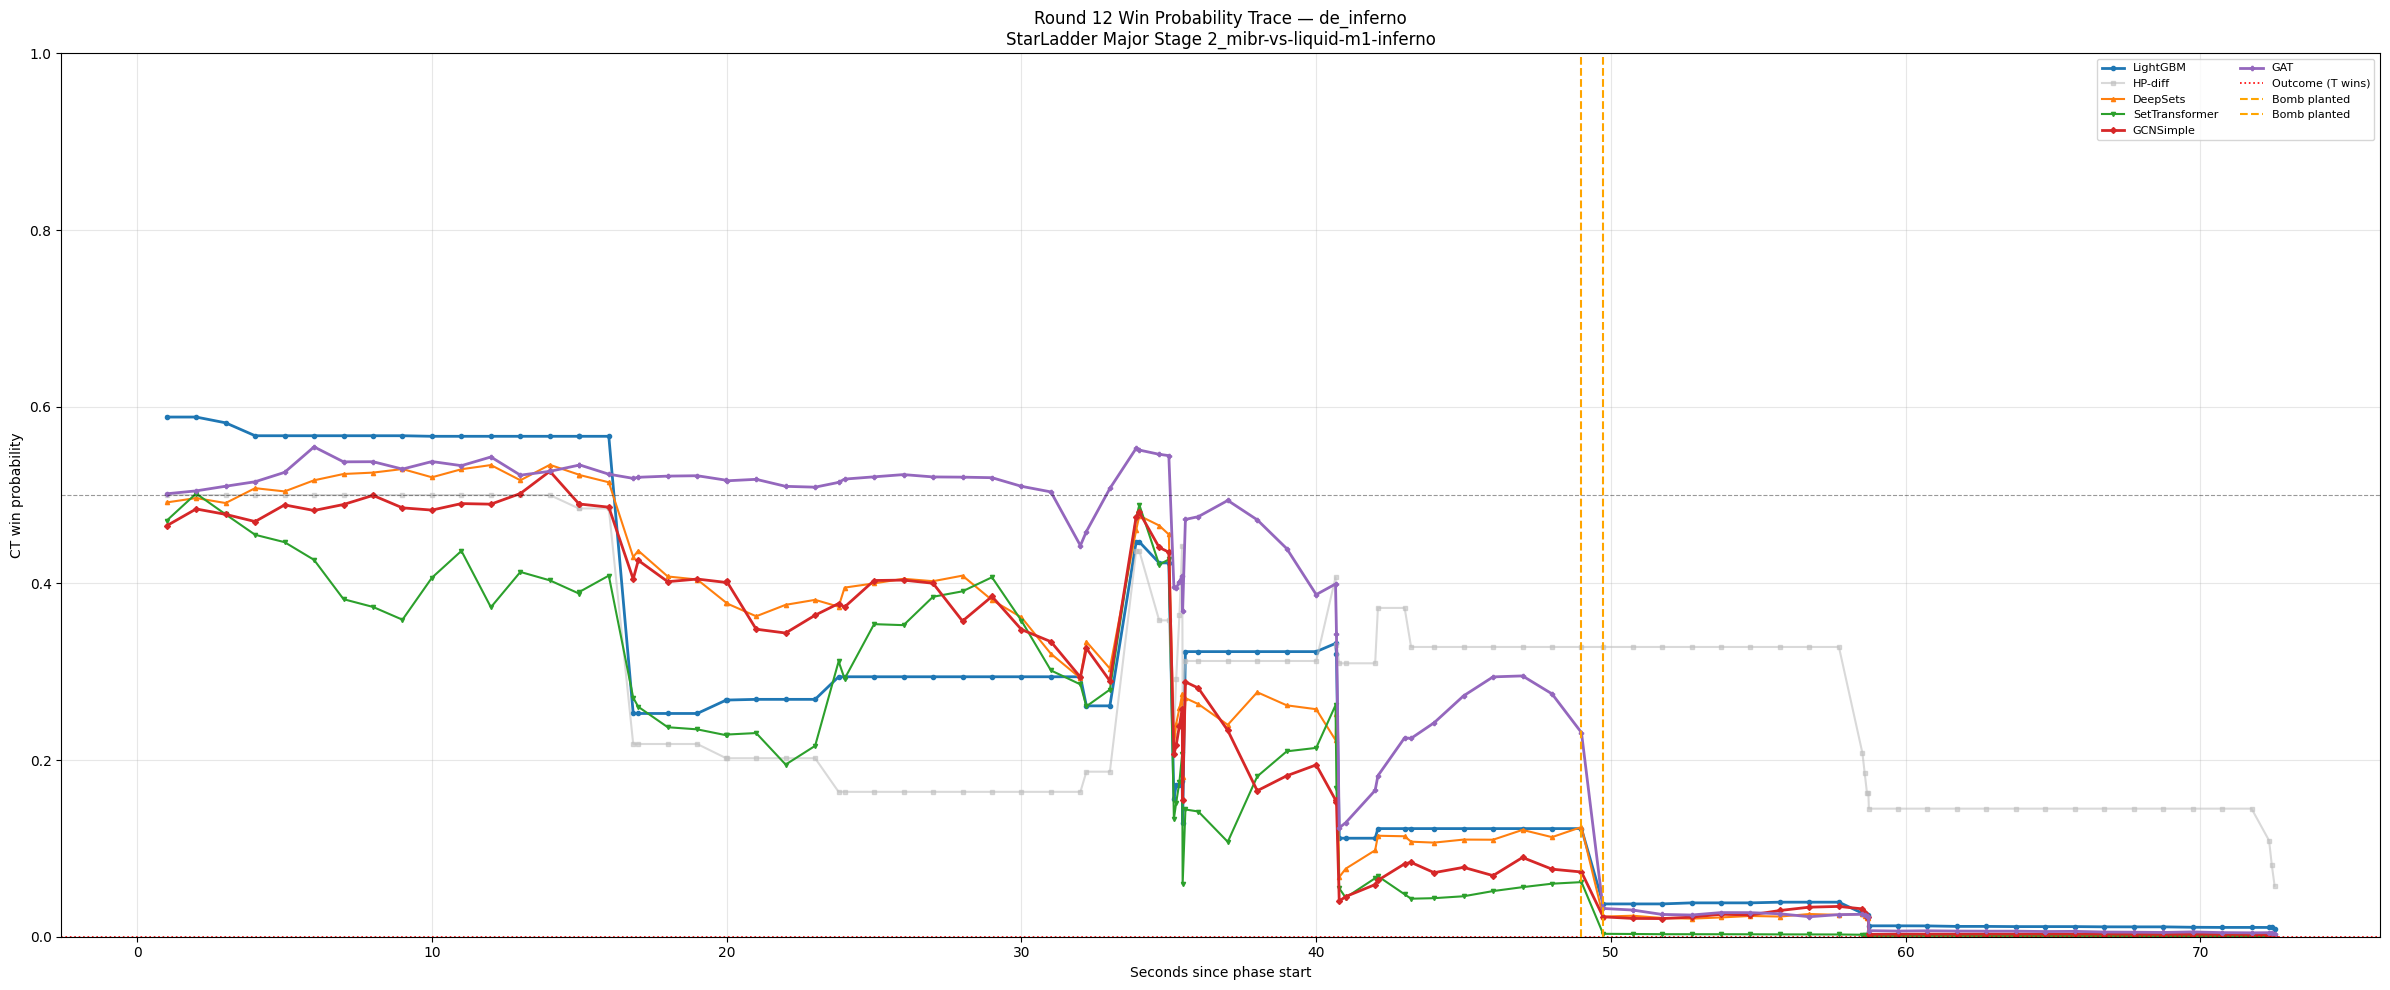

States in round: 97
Outcome: T wins
Bomb planted: yes


In [25]:
# ── Round win probability trace — all models ─────────────────────────────
MATCH_KEY = list(test_data.keys())[17]   # change to a specific match key
ROUND_NUM = 12
match = test_data[MATCH_KEY]

# Collect all state indices belonging to this round
round_idx = [i for i, df_row in enumerate(match['df'])
             if df_row.get('roundNum') == ROUND_NUM]

if not round_idx:
    print(f'Round {ROUND_NUM} not found in {MATCH_KEY}')
else:
    # Build a continuous time axis: pre-plant uses secondsSincePhaseStart directly,
# post-plant adds the pre-plant duration so they appear after on the x-axis
    preplant_duration = max(
        (float(match['df'][i].get('secondsSincePhaseStart', 0))
        for i in round_idx
        if not match['df'][i].get('bombPlanted', 0)),
        default=0.0
    )

    times = []
    for i in round_idx:
        t    = float(match['df'][i].get('secondsSincePhaseStart', 0))
        bomb = int(match['df'][i].get('bombPlanted', 0))
        times.append(preplant_duration + t if bomb else t)
    bombs  = [int(match['df'][i].get('bombPlanted', 0))              for i in round_idx]
    y_true = match['Y'][round_idx[0]]

    # ── LightGBM ─────────────────────────────────────────────────────────
    X_round = pd.DataFrame([match['df'][i] for i in round_idx])
    drop_cols = [c for c in ['tick', 'roundNum', 'ctWin'] if c in X_round.columns]
    X_round = X_round.drop(columns=drop_cols).fillna(0)
    lgbm_probs = lgbm_model.predict(X_round)

    # ── HP-diff baseline ─────────────────────────────────────────────────
    delta_h    = X_round['ctHp'].values - X_round['tHp'].values
    hpdiff_round = np.clip(1 / (1 + np.exp(-delta_h / tau_opt)), 1e-7, 1 - 1e-7)

    # ── DeepSets / SetTransformer ─────────────────────────────────────────
    # Load the normaliser that was fitted on the training set
    normaliser = datasets['set']['normaliser']

    round_set_probs = {}
    for model_name, set_model in [('DeepSets', deepsets_model),
                                   ('SetTransformer', settransformer_model)]:
        set_model.eval()
        preds = []
        with torch.no_grad():
            for i in round_idx:
                # match['X'][i] is a list of player vectors (already normalised
                # by SetNormaliser during build_datasets — re-apply manually here
                # since we're going directly from raw JSON)
                x_raw = np.array(match['X'][i], dtype=np.float32)   # (N, 32)
                x_norm = normaliser.transform(x_raw)                  # (N, 32)
                xb = torch.tensor(x_norm, dtype=torch.float32).unsqueeze(0).to(DEVICE)  # (1, N, 32)
                logit = set_model(xb)
                preds.append(torch.sigmoid(logit).item())
        round_set_probs[model_name] = np.array(preds)

    # ── GCNSimple / GAT ───────────────────────────────────────────────────
    round_graph_probs = {}
    for model_name, graph_model in [('GCNSimple', gcn_simple_model),
                                     ('GAT', gat_model)]:
        graph_model.eval()
        preds = []
        with torch.no_grad():
            for i in round_idx:
                g = match['GNN'][i]
                x          = torch.tensor(g['x'],          dtype=torch.float32)
                edge_index = torch.tensor(g['edge_index'],  dtype=torch.long)
                edge_attr  = torch.tensor(g['edge_attr'],   dtype=torch.float32)
                # Normalise node features with the same SetNormaliser
                # x = torch.tensor(
                #     normaliser.transform(x.numpy()), dtype=torch.float32
                # )
                data = Data(x=x, edge_index=edge_index, edge_attr=edge_attr,
                            y=torch.tensor([y_true], dtype=torch.float32))
                data = data.to(DEVICE)
                # Wrap in a single-graph batch (global_mean_pool needs batch vector)
                from torch_geometric.data import Batch
                batch = Batch.from_data_list([data.cpu()]).to(DEVICE)
                logit = graph_model(batch)
                preds.append(torch.sigmoid(logit).item())
        round_graph_probs[model_name] = np.array(preds)

    # ── Plot ──────────────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(24, 10))

    ax.plot(times, lgbm_probs,              '-o',  ms=3, lw=2,   color=COLORS['LightGBM'],      label='LightGBM')
    ax.plot(times, hpdiff_round,            '-s',  ms=3, lw=1.5, color=COLORS['HP-diff'],        label='HP-diff', alpha=0.6)
    ax.plot(times, round_set_probs['DeepSets'],    '-^', ms=3, lw=1.5, color=COLORS['DeepSets'],       label='DeepSets')
    ax.plot(times, round_set_probs['SetTransformer'], '-v', ms=3, lw=1.5, color=COLORS['SetTransformer'], label='SetTransformer')
    ax.plot(times, round_graph_probs['GCNSimple'], '-D', ms=3, lw=2,   color=COLORS['GCNSimple'],     label='GCNSimple')
    ax.plot(times, round_graph_probs['GAT'],       '-P', ms=3, lw=2,   color=COLORS['GAT'],           label='GAT')

    ax.axhline(0.5,    color='k',                          lw=0.8, ls='--', alpha=0.4)
    ax.axhline(y_true, color='green' if y_true == 1 else 'red', lw=1.2, ls=':',
               label=f'Outcome ({"CT wins" if y_true == 1 else "T wins"})')

    plant_idx = next((i for i, b in enumerate(bombs) if b == 1), None)
    if plant_idx is not None:
        ax.axvline(times[plant_idx], color='orange', lw=1.5, ls='--', label='Bomb planted')
    ax.axvline(preplant_duration, color='orange', lw=1.5, ls='--', label='Bomb planted')
    ax.set_xlabel('Seconds since round start (post-plant time offset)')
    ax.set_xlabel('Seconds since phase start')
    ax.set_ylabel('CT win probability')
    ax.set_title(f'Round {ROUND_NUM} Win Probability Trace — de_{MAP_NAME}\n{MATCH_KEY}')
    ax.set_ylim(0, 1)
    ax.legend(fontsize=8, ncol=2)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(CHECKPOINT_DIR / f'fig_round_trace_r{ROUND_NUM}.png', dpi=150, bbox_inches='tight')
    plt.show()

    print(f'States in round: {len(round_idx)}')
    print(f'Outcome: {"CT wins" if y_true == 1 else "T wins"}')
    print(f'Bomb planted: {"yes" if plant_idx is not None else "no"}')

## 9. Temporal GNN  *(run in a separate session)*

RAM-heavy — run alone on A100 if available (removes max_seq_len=80 cap).
Use `lr_temporal=3e-4` and `grad_clip_temporal=0.5` from the start.

In [ ]:
from torch.utils.data import DataLoader as TorchDataLoader

temporal_train = TemporalGraphDataset(train_data, max_len=CFG['max_seq_len'])
temporal_val   = TemporalGraphDataset(val_data,   max_len=CFG['max_seq_len'])
temporal_test  = TemporalGraphDataset(test_data,  max_len=CFG['max_seq_len'])
print(f'Temporal: train={len(temporal_train)} val={len(temporal_val)} test={len(temporal_test)} rounds')


In [ ]:
tgnn_ckpt = CHECKPOINT_DIR / 'temporal_gnn.pt'
temporal_model = TemporalGNN(hidden=128).to(DEVICE)

if tgnn_ckpt.exists():
    print('  Checkpoint found → loading')
    temporal_model.load_state_dict(torch.load(tgnn_ckpt, map_location=DEVICE))
    temporal_model.eval()
else:
    optim = Adam(temporal_model.parameters(),
                 lr=CFG['lr_temporal'], weight_decay=CFG['weight_decay'])
    crit  = nn.BCEWithLogitsLoss()
    train_loader = TorchDataLoader(temporal_train, batch_size=CFG['batch_size'],
                                   shuffle=True, collate_fn=temporal_collate_fn)
    val_loader   = TorchDataLoader(temporal_val,   batch_size=CFG['batch_size'],
                                   shuffle=False, collate_fn=temporal_collate_fn)
    best_val, best_ep, no_improve = float('inf'), 0, 0

    for ep in range(1, CFG['epochs'] + 1):
        temporal_model.train()
        tot_loss, tot_n = 0.0, 0
        for ts_batches, masks, labels in train_loader:
            lbl = labels.float().unsqueeze(1).to(DEVICE)
            optim.zero_grad()
            loss = crit(temporal_model(ts_batches, masks, lbl.size(0)), lbl)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(temporal_model.parameters(), CFG['grad_clip_temporal'])
            optim.step()
            tot_loss += loss.item() * lbl.size(0); tot_n += lbl.size(0)

        temporal_model.eval()
        val_probs, val_trues = [], []
        with torch.no_grad():
            for ts_batches, masks, labels in val_loader:
                lbl = labels.float().unsqueeze(1).to(DEVICE)
                logits = temporal_model(ts_batches, masks, lbl.size(0))
                val_probs.append(torch.sigmoid(logits).cpu().numpy().flatten())
                val_trues.append(labels.numpy().flatten())
        val_ll = log_loss(np.concatenate(val_trues), np.concatenate(val_probs))
        print(f'  Epoch {ep:3d}  train LL={tot_loss/tot_n:.4f}  val LL={val_ll:.4f}')

        if val_ll < best_val:
            best_val, best_ep, no_improve = val_ll, ep, 0
            torch.save(temporal_model.state_dict(), tgnn_ckpt)
        else:
            no_improve += 1
            if no_improve >= CFG['patience']:
                print(f'  Early stop at epoch {ep} (best epoch {best_ep}, val LL={best_val:.4f})')
                break

    temporal_model.load_state_dict(torch.load(tgnn_ckpt, map_location=DEVICE))
    temporal_model.eval()


In [ ]:
def train_temporal_gnn(
    temporal_train, temporal_val,
    cfg, checkpoint_path, device
):
    """
    temporal_train / temporal_val: list of (round_graphs, label)
    cfg: TEMPORAL_CFG dict
    """
    model = TemporalGNN(
        hidden       = cfg['hidden'],
        num_node_feat= cfg['num_node_feat'],
        drop_edge_p  = cfg['drop_edge_p'],
        dropout_gcn  = cfg['dropout_gcn'],
    ).to(device)

    optim = Adam(model.parameters(), lr=cfg['lr'], weight_decay=cfg['weight_decay'])
    crit  = nn.BCEWithLogitsLoss()

    # Partial collate binding model and device
    from functools import partial
    collate = partial(
        temporal_collate_fn,
        model      = model,
        device     = device,
        max_seq_len= cfg['max_seq_len'],
    )

    train_loader = TorchDataLoader(
        temporal_train, batch_size=cfg['batch_size'],
        shuffle=True,  collate_fn=collate
    )
    val_loader = TorchDataLoader(
        temporal_val, batch_size=cfg['batch_size'],
        shuffle=False, collate_fn=collate
    )

    best_val, best_ep, no_improve = float('inf'), 0, 0

    for ep in range(1, cfg['epochs'] + 1):

        # ── train ──────────────────────────────────────────────────────────
        model.train()
        tot_loss, tot_n = 0.0, 0

        for seq, mask, labels in train_loader:
            seq, mask = seq.to(device), mask.to(device)
            lbl = labels.float().unsqueeze(1).to(device)

            optim.zero_grad()
            logits = model(seq, mask)
            loss   = crit(logits, lbl)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg['grad_clip'])
            optim.step()

            tot_loss += loss.item() * lbl.size(0)
            tot_n    += lbl.size(0)

        train_ll = tot_loss / tot_n

        # ── val ────────────────────────────────────────────────────────────
        model.eval()
        val_probs, val_trues = [], []

        with torch.no_grad():
            for seq, mask, labels in val_loader:
                seq, mask = seq.to(device), mask.to(device)
                logits = model(seq, mask)
                probs  = torch.sigmoid(logits).cpu().numpy().flatten()
                val_probs.append(probs)
                val_trues.append(labels.numpy().flatten())

        val_ll = log_loss(
            np.concatenate(val_trues),
            np.clip(np.concatenate(val_probs), 1e-7, 1 - 1e-7)
        )

        print(f'  Epoch {ep:3d}  train LL={train_ll:.4f}  val LL={val_ll:.4f}')

        if val_ll < best_val:
            best_val, best_ep, no_improve = val_ll, ep, 0
            torch.save(model.state_dict(), checkpoint_path)
        else:
            no_improve += 1
            if no_improve >= cfg['patience']:
                print(f'  Early stop at epoch {ep} (best epoch {best_ep}, val LL={best_val:.4f})')
                break

    model.load_state_dict(torch.load(checkpoint_path, map_location=device))
    model.eval()
    return model

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)  # confirm it says cuda

model = train_temporal_gnn(
    temporal_train,
    temporal_val,
    TEMPORAL_CFG,
    CHECKPOINT_DIR / 'temporal_gnn.pt',
    device
)

In [ ]:
from functools import partial

# Load best checkpoint
model.load_state_dict(torch.load(CHECKPOINT_DIR / 'temporal_gnn.pt', map_location=device))
model.eval()

collate = partial(
    temporal_collate_fn,
    model=model,
    device=device,
    max_seq_len=TEMPORAL_CFG['max_seq_len'],
)

test_loader = TorchDataLoader(
    temporal_test, batch_size=TEMPORAL_CFG['batch_size'],
    shuffle=False, collate_fn=collate
)

test_probs, test_trues = [], []
with torch.no_grad():
    for seq, mask, labels in test_loader:
        seq, mask = seq.to(device), mask.to(device)
        probs = torch.sigmoid(model(seq, mask)).cpu().numpy().flatten()
        test_probs.append(probs)
        test_trues.append(labels.numpy().flatten())

test_ll  = log_loss(np.concatenate(test_trues), np.clip(np.concatenate(test_probs), 1e-7, 1-1e-7))
test_ece = compute_ece(np.concatenate(test_trues), np.concatenate(test_probs))
print(f'[TemporalGNN/test]  LL={test_ll:.4f}  ECE={test_ece:.4f}')

In [ ]:
def predict_round_trace(model, round_graphs, device, max_seq_len=80):
    """
    Returns a probability trace over time for a single round.
    round_graphs: list of PyG Data objects, one per tick
    """
    model.eval()
    H = model.gru.hidden_size
    T = min(len(round_graphs), max_seq_len)

    from torch_geometric.data import Batch as PyGBatch

    # Encode all graphs
    g_batch = PyGBatch.from_data_list(round_graphs[:T]).to(device)
    with torch.no_grad():
        embs = model.encode_graph(g_batch, apply_drop_edge=False)  # (T, H)

    # Run GRU over the full sequence
    seq = embs.unsqueeze(0)          # (1, T, H)
    with torch.no_grad():
        gru_out, _ = model.gru(seq)  # (1, T, H)
        logits = model.head(gru_out.squeeze(0))  # (T, 1)
        probs  = torch.sigmoid(logits).squeeze(1).cpu().numpy()  # (T,)

    return probs

# Run on your example round — find it in temporal_test by round identifier
# Assuming you know its index:
example_graphs, example_label = temporal_test[15]
trace = predict_round_trace(model, example_graphs, device)

# Plot alongside the static GCNSimple trace you already have
import matplotlib.pyplot as plt
ticks = np.arange(len(trace))
plt.figure(figsize=(12, 4))
plt.plot(ticks, trace, label='TemporalGNN', color='#9467bd', linewidth=1.5)
plt.axhline(0.5, color='gray', linestyle='--', linewidth=0.8)
plt.xlabel('Tick (seconds since round start)')
plt.ylabel('CT win probability')
plt.title(f'Round trace — TemporalGNN (true outcome: {"CT" if example_label else "T"})')
plt.legend()
plt.tight_layout()
plt.show()